# Лабораторная работа №1 — Классификация

Credit Risk Dataset. Ноутбук содержит вычислительный код и сохранённые результаты эксперимента. Выполняйте ячейки сверху вниз. По умолчанию показываются ранее рассчитанные результаты; для повторного обучения установите `REBUILD = True` (расчёт может занять несколько минут).

In [2]:
from pathlib import Path
import sys, os, json
import pandas as pd
from IPython.display import display, Image, Markdown

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/raw/credit_risk_dataset.csv').exists()), None)
if PROJECT is None:
    raise RuntimeError('Откройте ноутбук из папки проекта ОМО')
LAB = PROJECT / 'Лаба1'
sys.path.insert(0, str(LAB))
REBUILD = False


## Данные и очистка
Одна строка — кредит. Удаляем строки с пропусками и полные дубликаты. В моделях масштабирование и кодирование выполняются отдельно от этой демонстрации.

In [4]:
raw = pd.read_csv(PROJECT / 'data/raw/credit_risk_dataset.csv')
display(raw.head())
display(raw.isna().sum().rename('Пропуски').to_frame())
clean = raw.dropna().drop_duplicates()
print(f'Исходных строк: {len(raw)}; после очистки: {len(clean)}')


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


,Пропуски
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


Исходных строк: 32581; после очистки: 28501


## Предварительная обработка и исследование признаков
Гистограммы, ящики с усами, диаграммы рассеяния и корреляция. Min–Max CSV служит отдельным результатом предобработки; классификаторы используют StandardScaler внутри Pipeline.

In [6]:
__file__ = str(LAB / 'preprocessing.py')
"""Учебная предварительная обработка Credit Risk Dataset.

Запуск: python preprocessing.py
"""

import json
import os
from pathlib import Path

ROOT = Path(__file__).resolve().parent
DATA = ROOT.parent / "data"
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


FEATURES = [
    "person_age", "person_income", "person_emp_length", "loan_amnt",
    "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length",
]
TARGET = "loan_status"


def save_figure(path: Path) -> None:
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.close()


def visualize(data: pd.DataFrame, directory: Path) -> None:
    """Распределения и связь признаков с дефолтом до/после очистки."""
    directory.mkdir(parents=True, exist_ok=True)
    fig, axes = plt.subplots(3, 3, figsize=(15, 12))
    for ax, feature in zip(axes.flat, FEATURES):
        sns.histplot(data=data, x=feature, bins=40, ax=ax)
    for ax in list(axes.flat)[len(FEATURES):]:
        ax.set_visible(False)
    save_figure(directory / "histograms.png")

    fig, axes = plt.subplots(3, 3, figsize=(15, 12))
    for ax, feature in zip(axes.flat, FEATURES):
        sns.boxplot(data=data, x=TARGET, y=feature, ax=ax)
    for ax in list(axes.flat)[len(FEATURES):]:
        ax.set_visible(False)
    save_figure(directory / "boxplots.png")

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    pairs = [("person_income", "loan_amnt"),
             ("person_age", "person_emp_length"),
             ("loan_int_rate", "loan_percent_income")]
    for ax, (x, y) in zip(axes, pairs):
        sns.scatterplot(data=data, x=x, y=y, hue=TARGET,
                        palette={0: "steelblue", 1: "darkorange"},
                        alpha=0.25, s=12, ax=ax)
    save_figure(directory / "scatterplots.png")


def main() -> None:
    sns.set_theme(style="whitegrid")
    raw = pd.read_csv(DATA / "raw/credit_risk_dataset.csv")
    output = DATA / "processed"
    figures = ROOT / "reports/figures"
    output.mkdir(parents=True, exist_ok=True)
    visualize(raw, figures / "raw")

    complete = raw.dropna().copy()
    clean = complete.drop_duplicates().copy()
    clean.to_csv(output / "credit_risk_clean.csv", index=False)
    visualize(clean, figures / "clean")

    minimum = clean[FEATURES].min()
    maximum = clean[FEATURES].max()
    span = (maximum - minimum).replace(0, 1)
    normalized = clean.copy()
    normalized[FEATURES] = (clean[FEATURES] - minimum) / span
    normalized.to_csv(output / "credit_risk_normalized.csv", index=False)

    correlation = clean[FEATURES + [TARGET]].corr(method="pearson")
    correlation.to_csv(output / "correlation.csv")
    plt.figure(figsize=(11, 9))
    sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, center=0, square=True)
    save_figure(figures / "correlation_matrix.png")

    report = {
        "original_rows": len(raw),
        "missing_by_column": raw.isna().sum().to_dict(),
        "removed_missing_rows": len(raw) - len(complete),
        "removed_duplicate_rows": len(complete) - len(clean),
        "clean_rows": len(clean),
        "normalization_min": minimum.to_dict(),
        "normalization_max": maximum.to_dict(),
        "employment_exceeds_age_rows": int(
            (clean.person_emp_length > clean.person_age).sum()
        ),
    }
    (output / "preprocessing_report.json").write_text(
        json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print(json.dumps(report, ensure_ascii=False, indent=2))


if REBUILD:
    main()


## Подготовка моделей
Цель — loan_status. Разделение 80/20 со стратификацией. Pipeline предотвращает утечку параметров преобразования. GridSearchCV выбирает KNN, SVM и дерево по F1 на трёх фолдах.

In [8]:
__file__ = str(LAB / 'classification.py')
"""Лабораторная №1: python classification.py."""

import json
import platform

import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, classification_report,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

from preprocessing import ROOT, DATA, FEATURES, TARGET, plt, save_figure, sns


def make_pipeline(model, categories):
    transform = ColumnTransformer([
        ("numeric", StandardScaler(), FEATURES),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categories),
    ])
    return Pipeline([("preprocess", transform), ("model", model)])



## Обучение и подбор параметров
Ниже приведено тело вычислительной программы, разбитое на последовательные ячейки. При `REBUILD=False` обучение пропускается. Для полного повторного расчёта измените флаг в первой ячейке и выполните Restart Kernel and Run All.

In [10]:
if REBUILD:
    sns.set_theme(style="whitegrid")

In [11]:
if REBUILD:
    output = ROOT / "reports/lab1"

In [12]:
if REBUILD:
    output.mkdir(parents=True, exist_ok=True)

In [13]:
if REBUILD:
    data = pd.read_csv(DATA / "raw/credit_risk_dataset.csv").dropna().drop_duplicates()

In [14]:
if REBUILD:
    x, y = data.drop(columns=TARGET), data[TARGET]

In [15]:
if REBUILD:
    categories = [column for column in x.columns if column not in FEATURES]

In [16]:
if REBUILD:
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, stratify=y, random_state=42
    )

In [17]:
if REBUILD:
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

In [18]:
if REBUILD:
    experiments = {
        "KNN": (KNeighborsClassifier(), {
            "model__n_neighbors": [5, 15, 31], "model__weights": ["uniform", "distance"]}),
        "SVM": (SVC(), [
            {"model__kernel": ["linear"], "model__C": [0.1, 1]},
            {"model__kernel": ["rbf"], "model__C": [1, 10], "model__gamma": ["scale", 0.01]},
        ]),
        "DecisionTree": (DecisionTreeClassifier(random_state=42), {
            "model__max_depth": [4, 8, 12, None],
            "model__min_samples_leaf": [5, 20],
            "model__class_weight": [None, "balanced"]}),
    }

In [19]:
if REBUILD:
    metrics, details = [], {}

In [20]:
if REBUILD:
    predictions = pd.DataFrame({"source_row": x_test.index, "actual": y_test.to_numpy()})

In [21]:
if REBUILD:
    fig_cm, axes = plt.subplots(1, 3, figsize=(16, 5))

In [22]:
if REBUILD:
    fig_roc, ax_roc = plt.subplots(figsize=(8, 6))

In [23]:
if REBUILD:
    tree_pipeline = None

In [24]:
if REBUILD:
    for ax, (name, (model, grid)) in zip(axes, experiments.items()):
        print(f"Training {name}...", flush=True)
        search = GridSearchCV(make_pipeline(model, categories), grid,
                              scoring="f1", cv=cv, n_jobs=2, error_score="raise")
        search.fit(x_train, y_train)
        best = search.best_estimator_
        predicted = best.predict(x_test)
        score = (best.decision_function(x_test) if name == "SVM"
                 else best.predict_proba(x_test)[:, 1])
        metrics.append({
            "model": name, "cv_f1": search.best_score_,
            "precision": precision_score(y_test, predicted, zero_division=0),
            "recall": recall_score(y_test, predicted, zero_division=0),
            "f1": f1_score(y_test, predicted, zero_division=0),
            "roc_auc": roc_auc_score(y_test, score),
        })
        details[name] = {"best_parameters": search.best_params_,
                         "classification_report": classification_report(
                             y_test, predicted, output_dict=True, zero_division=0)}
        pd.DataFrame(search.cv_results_).to_csv(output / f"{name}_cv.csv", index=False)
        predictions[f"{name}_predicted"] = predicted
        predictions[f"{name}_score"] = score
        ConfusionMatrixDisplay.from_predictions(y_test, predicted, ax=ax,
                                                colorbar=False, cmap="Blues")
        ax.set_title(name)
        ax.grid(False)
        RocCurveDisplay.from_predictions(y_test, score, name=name, ax=ax_roc)
        if name == "DecisionTree":
            tree_pipeline = best
        print(metrics[-1], flush=True)

In [25]:
if REBUILD:
    plt.figure(fig_cm.number)

In [26]:
if REBUILD:
    save_figure(output / "confusion_matrices.png")

In [27]:
if REBUILD:
    ax_roc.plot([0, 1], [0, 1], "k--", label="Random classifier")

In [28]:
if REBUILD:
    ax_roc.legend()

In [29]:
if REBUILD:
    plt.figure(fig_roc.number)

In [30]:
if REBUILD:
    save_figure(output / "roc_curves.png")

In [31]:
if REBUILD:
    plt.figure(figsize=(24, 12))

In [32]:
if REBUILD:
    plot_tree(tree_pipeline.named_steps["model"],
              feature_names=tree_pipeline.named_steps["preprocess"].get_feature_names_out(),
              class_names=["No default", "Default"], filled=True,
              max_depth=3, fontsize=8)

In [33]:
if REBUILD:
    plt.title("Decision tree: first 4 levels (thresholds after StandardScaler)")

In [34]:
if REBUILD:
    save_figure(output / "decision_tree.png")

In [35]:
if REBUILD:
    result = pd.DataFrame(metrics)

In [36]:
if REBUILD:
    result.to_csv(output / "metrics.csv", index=False)

In [37]:
if REBUILD:
    predictions.to_csv(output / "predictions.csv", index=False)

In [38]:
if REBUILD:
    winner = result.loc[result.cv_f1.idxmax(), "model"]

In [39]:
if REBUILD:
    details["experiment"] = {
        "python": platform.python_version(), "sklearn": sklearn.__version__,
        "train_rows": len(x_train), "test_rows": len(x_test),
        "train_class_counts": y_train.value_counts().to_dict(),
        "test_class_counts": y_test.value_counts().to_dict(),
        "selected_by_cv_f1": winner, "random_state": 42,
        "tree_depth": tree_pipeline.named_steps["model"].get_depth(),
    }

In [40]:
if REBUILD:
    (output / "results.json").write_text(
        json.dumps(details, ensure_ascii=False, indent=2), encoding="utf-8")

In [41]:
if REBUILD:
    print(result.to_string(index=False))

In [42]:
if REBUILD:
    print(f"Selected by CV F1: {winner}")

## Оценка результатов
Метрики ниже загружаются из сохранённых файлов; после повторного обучения они обновляются.

In [44]:
RESULTS = LAB / 'reports/lab1'
display(pd.read_csv(RESULTS / 'metrics.csv'))
display(json.loads((RESULTS / 'results.json').read_text(encoding='utf-8'))) 

,model,cv_f1,precision,recall,f1,roc_auc
0,KNN,0.709947,0.881499,0.588853,0.706053,0.877060
1,SVM,0.779121,0.912027,0.661551,0.766854,0.901038
2,DecisionTree,0.802951,0.975862,0.685784,0.805503,0.909241


{'KNN': {'best_parameters': {'model__n_neighbors': 15, 'model__weights': 'distance'}, 'classification_report': {'0': {'precision': 0.8955683217070168, 'recall': 0.9780416760026888, 'f1-score': 0.9349898254257256, 'support': 4463.0}, '1': {'precision': 0.8814993954050786, 'recall': 0.5888529886914378, 'f1-score': 0.7060532687651332, 'support': 1238.0}, 'accuracy': 0.8935274513243291, 'macro avg': {'precision': 0.8885338585560477, 'recall': 0.7834473323470632, 'f1-score': 0.8205215470954295, 'support': 5701.0}, 'weighted avg': {'precision': 0.8925131856323283, 'recall': 0.8935274513243291, 'f1-score': 0.8852751337671019, 'support': 5701.0}}}, 'SVM': {'best_parameters': {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}, 'classification_report': {'0': {'precision': 0.9127628565479908, 'recall': 0.9822989020838001, 'f1-score': 0.9462551262680768, 'support': 4463.0}, '1': {'precision': 0.9120267260579065, 'recall': 0.6615508885298869, 'f1-score': 0.7668539325842697, 'support'

## Графики
Изображения — фактические результаты сохранённого эксперимента.

### confusion_matrices

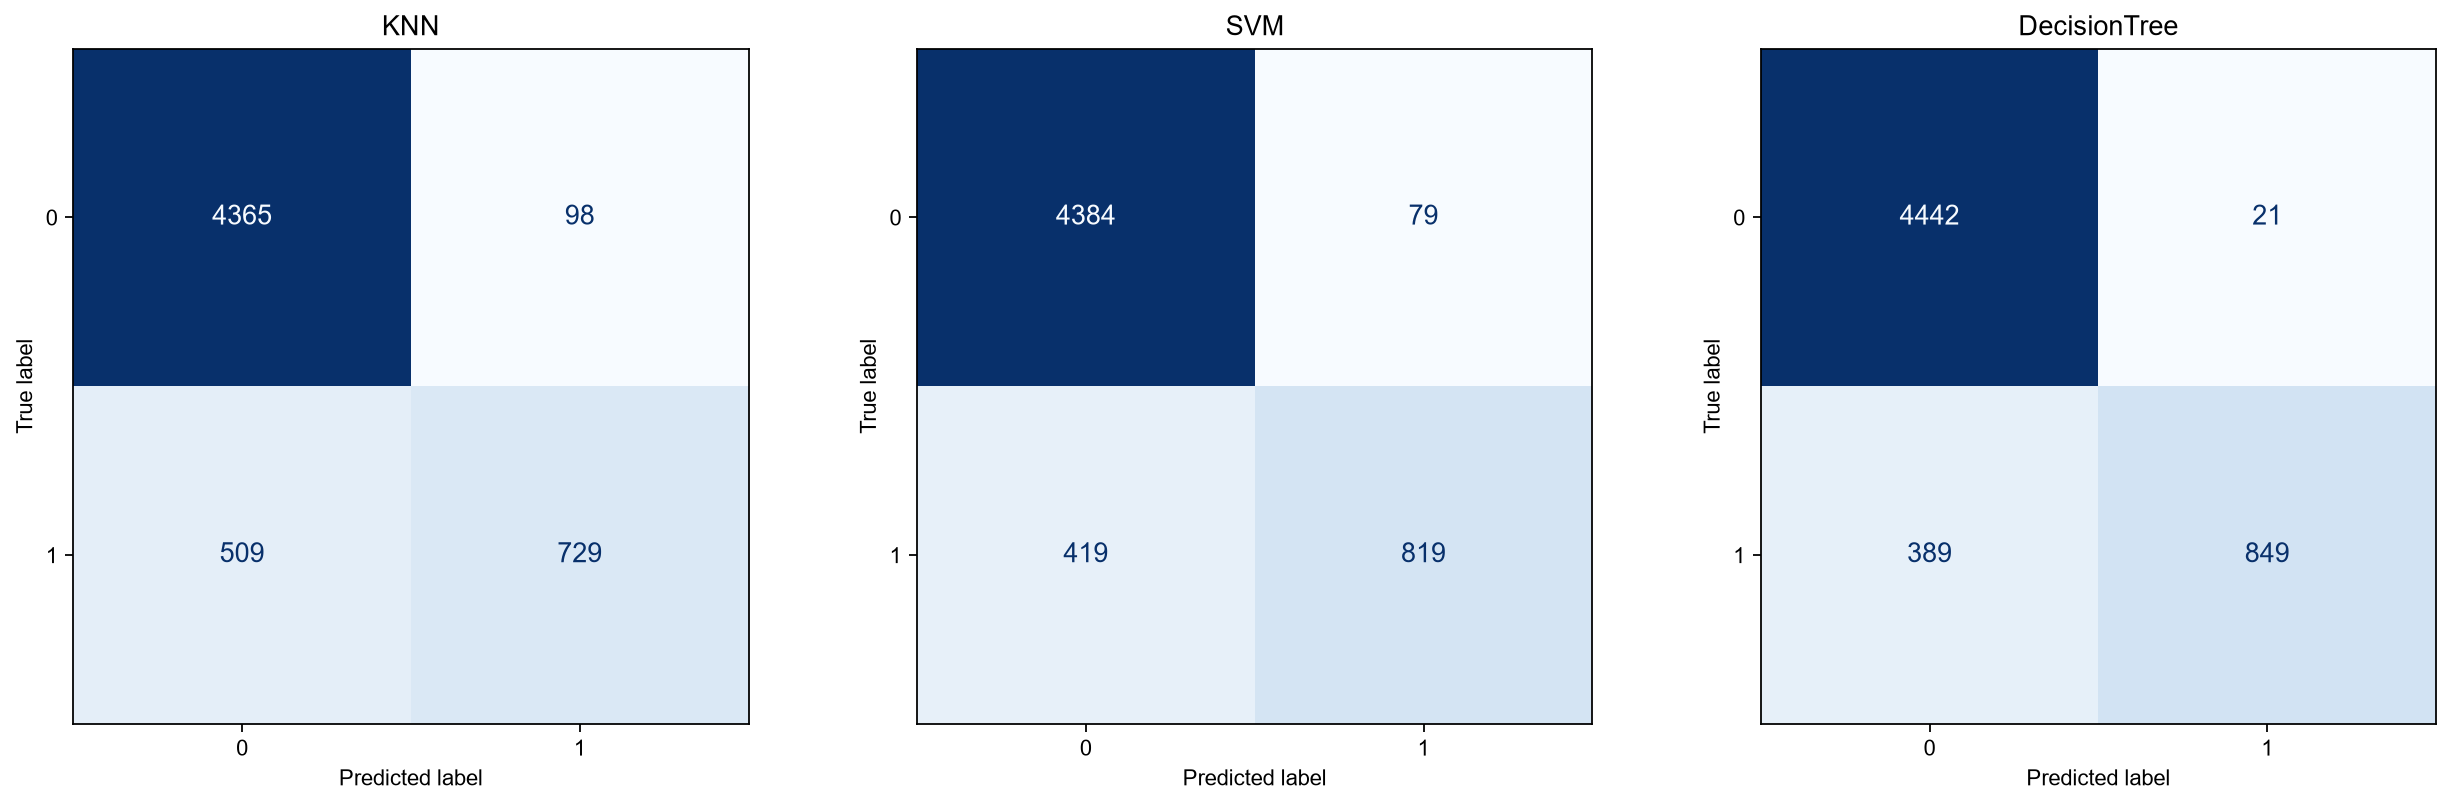

In [47]:
display(Image(filename=str(LAB / 'reports/lab1/confusion_matrices.png')))

### decision_tree

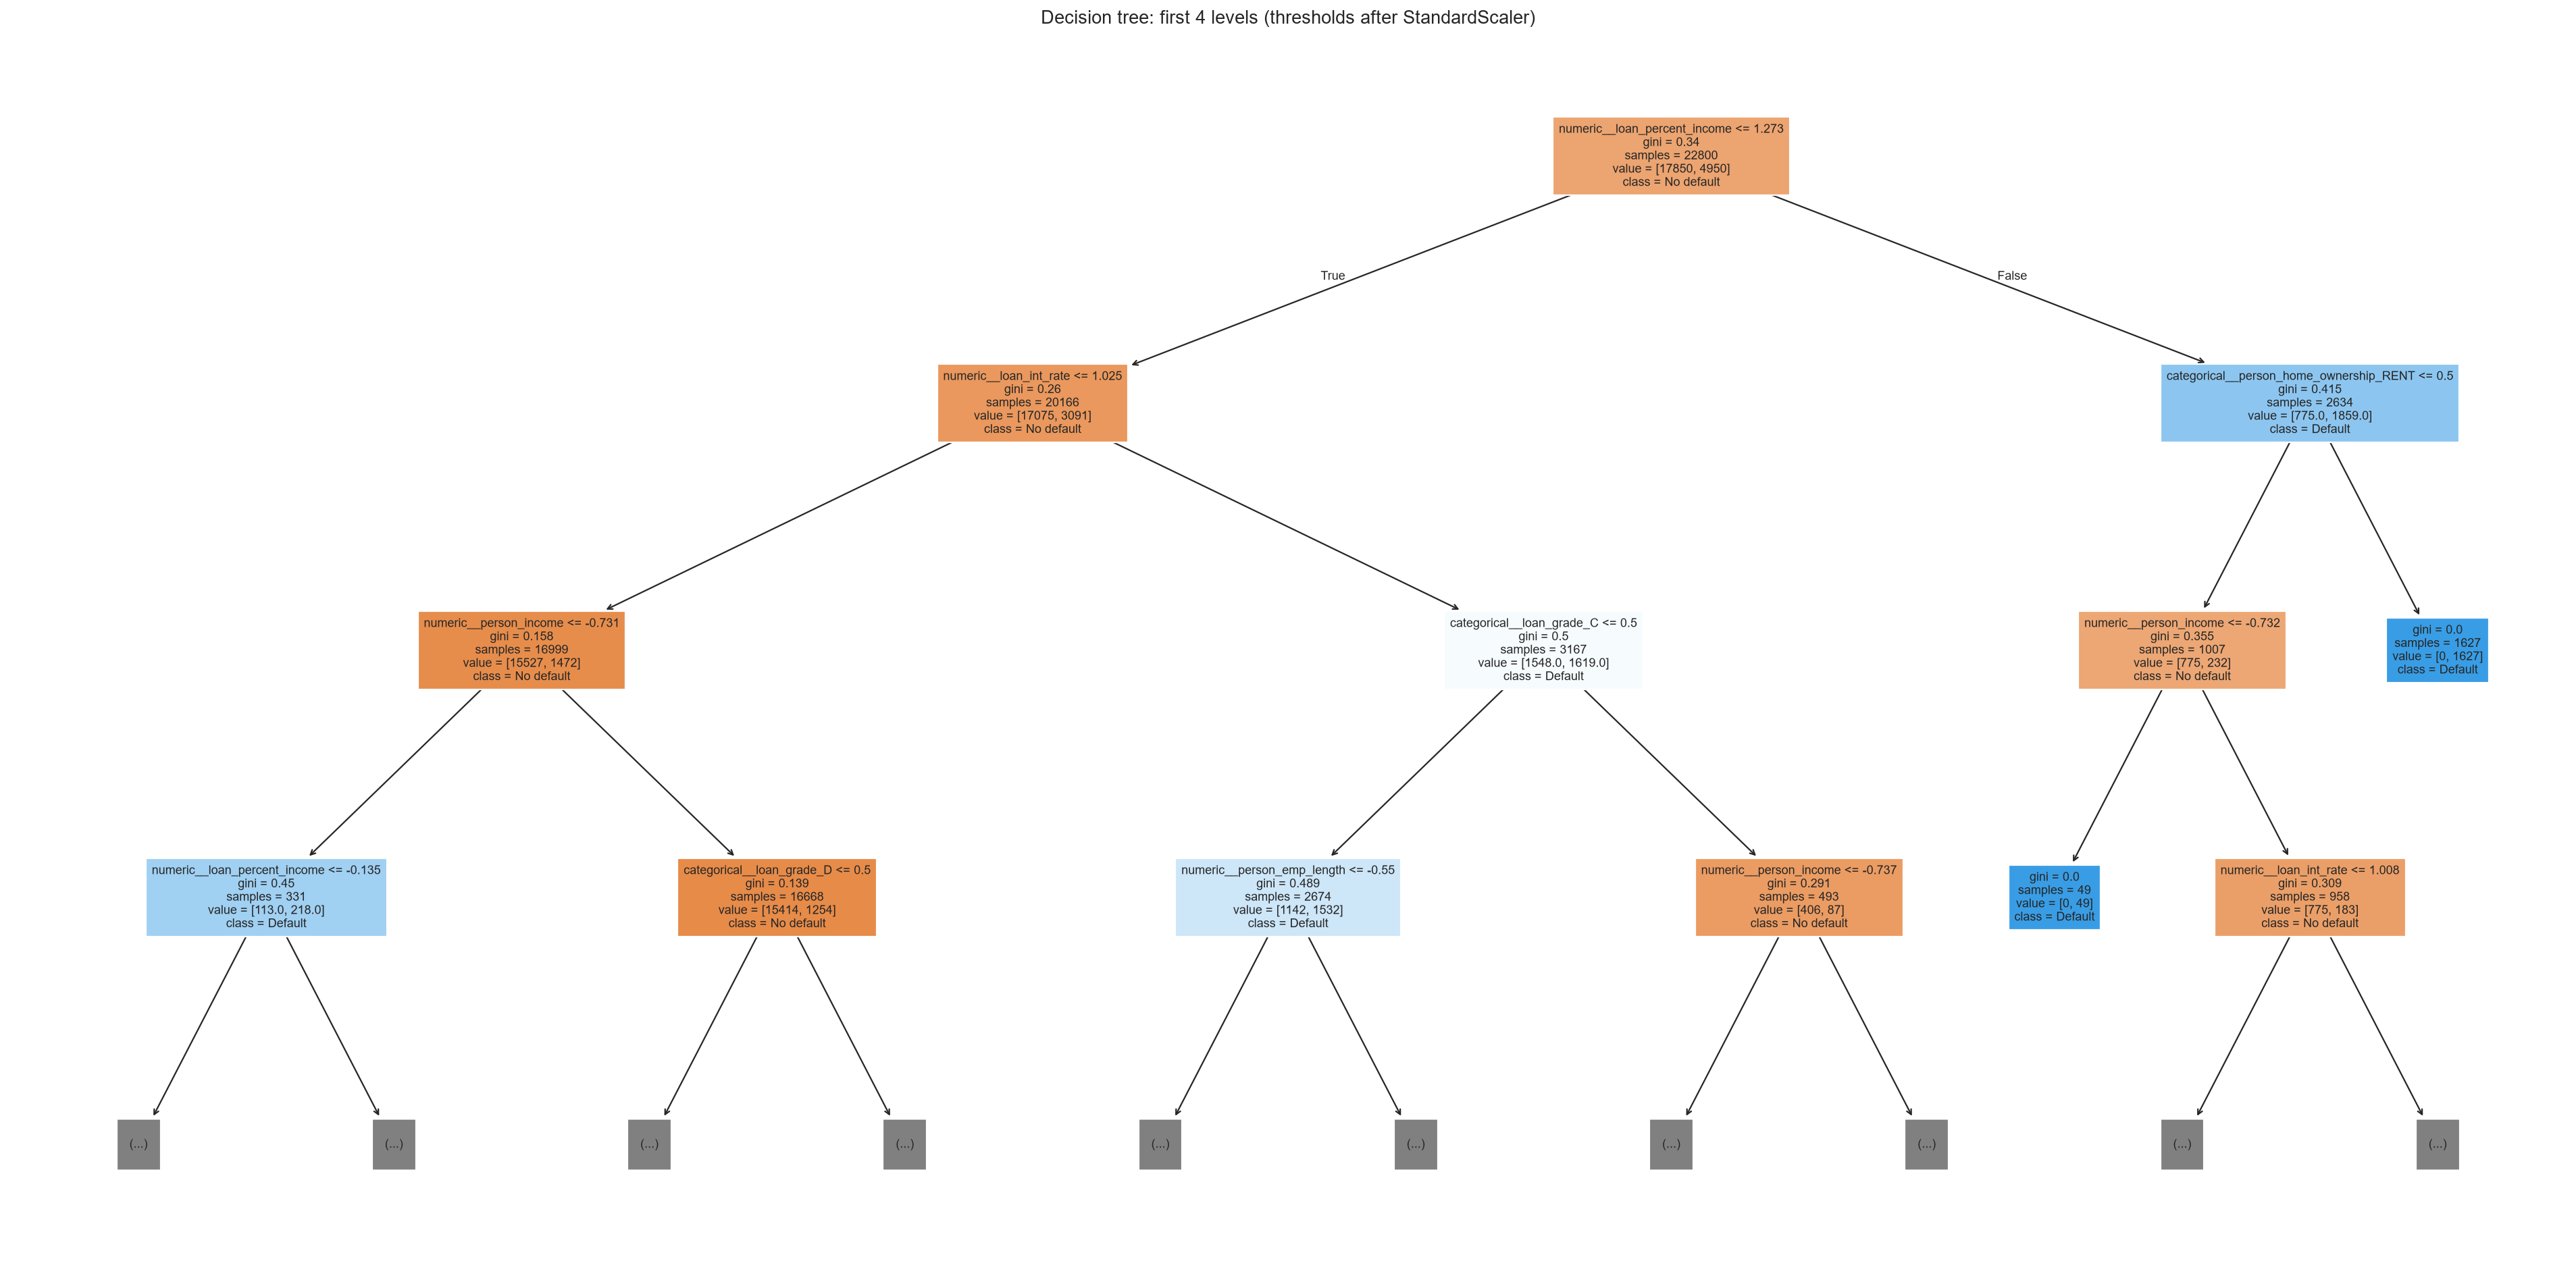

In [49]:
display(Image(filename=str(LAB / 'reports/lab1/decision_tree.png')))

### roc_curves

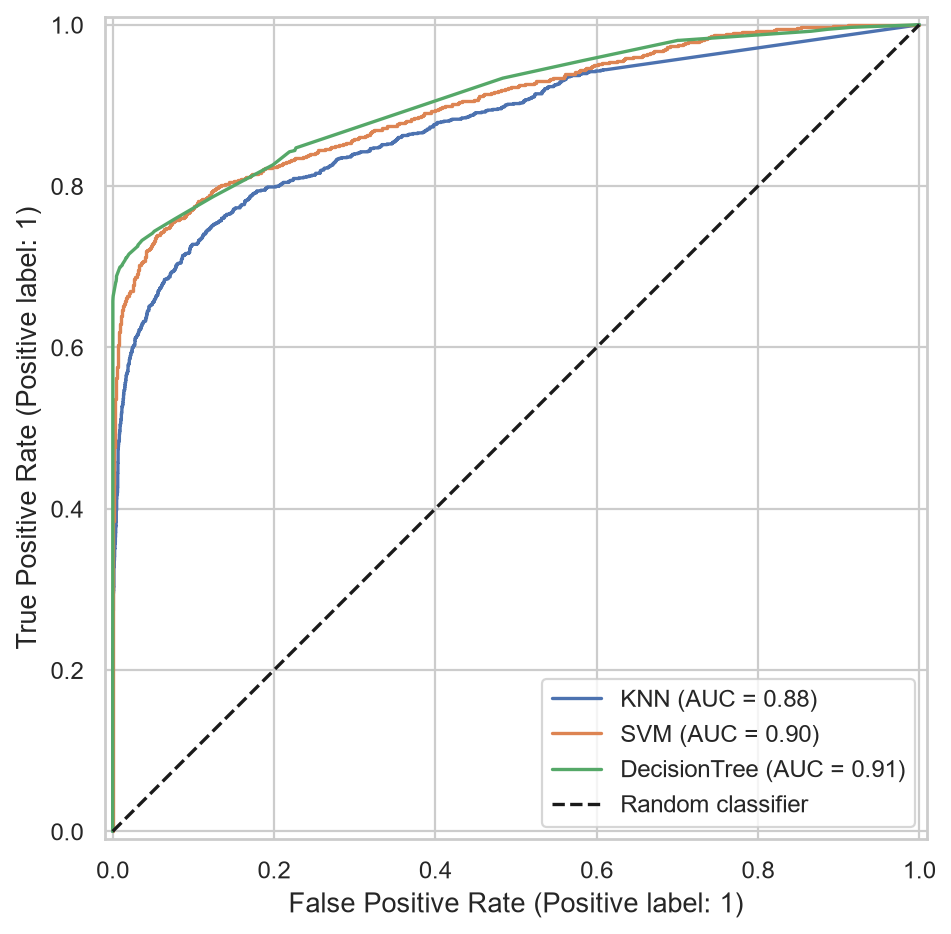

In [51]:
display(Image(filename=str(LAB / 'reports/lab1/roc_curves.png')))

### boxplots

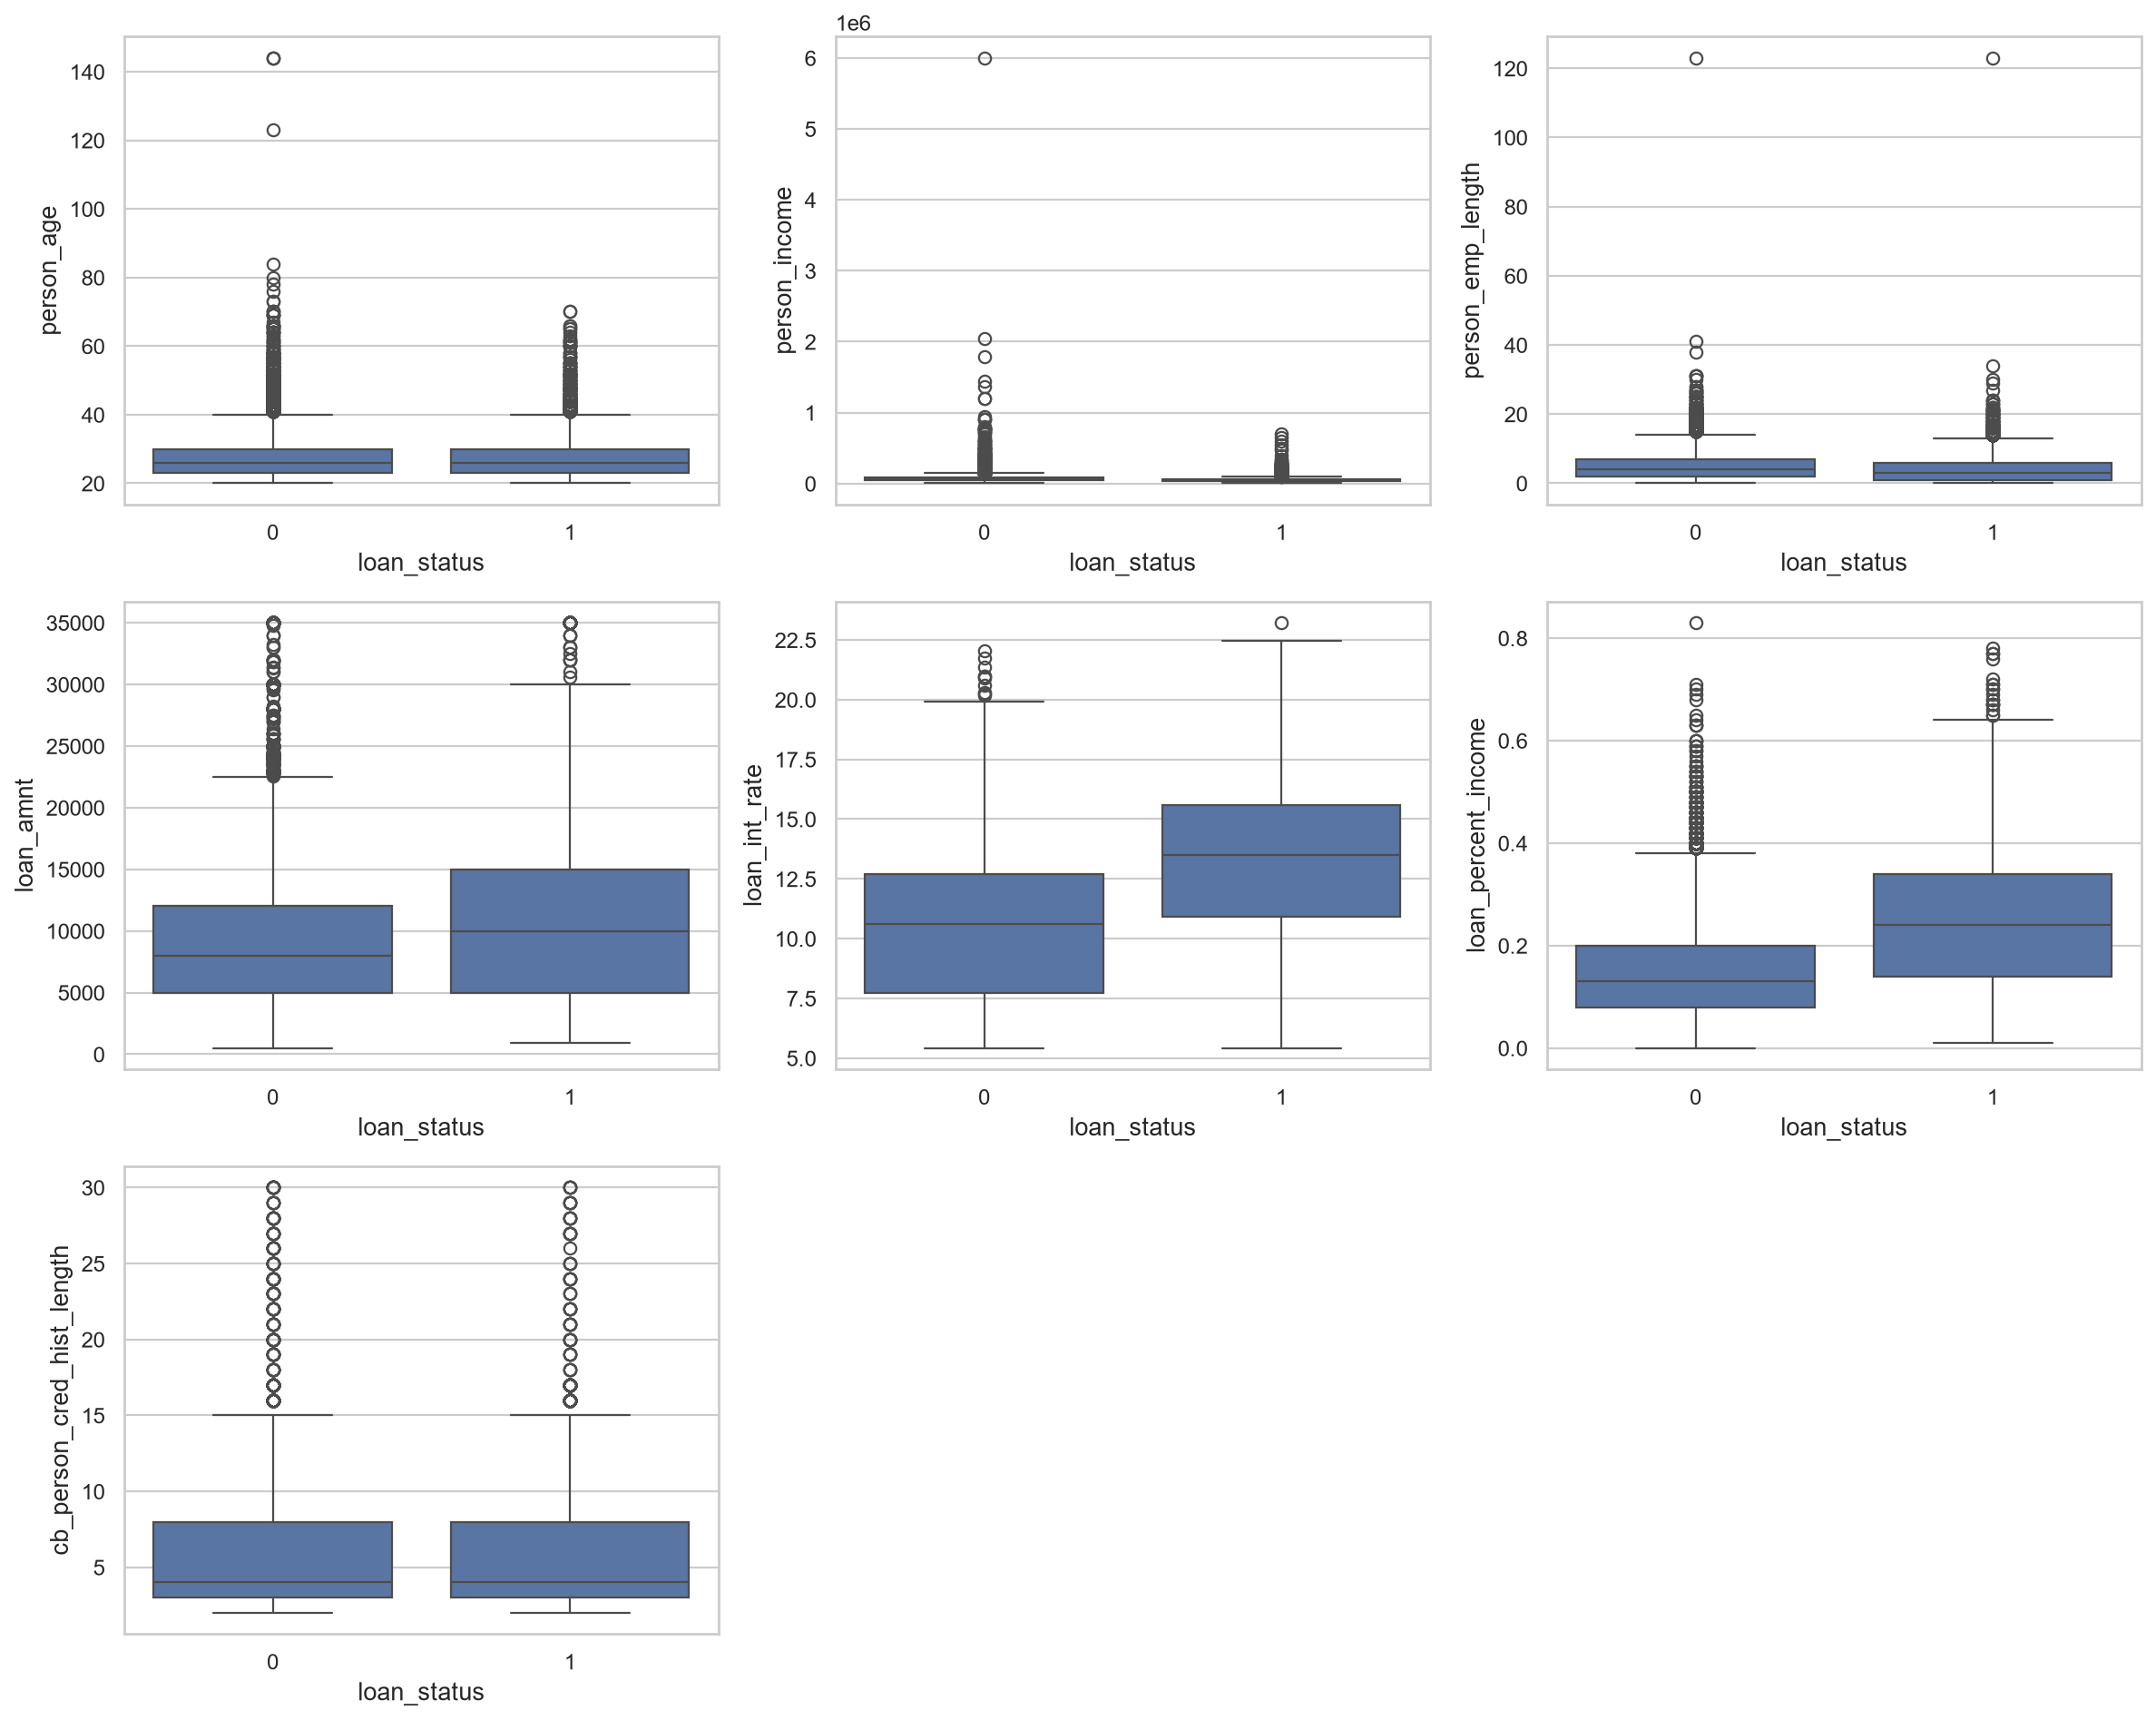

In [53]:
display(Image(filename=str(LAB / 'reports/figures/clean/boxplots.png')))

### histograms

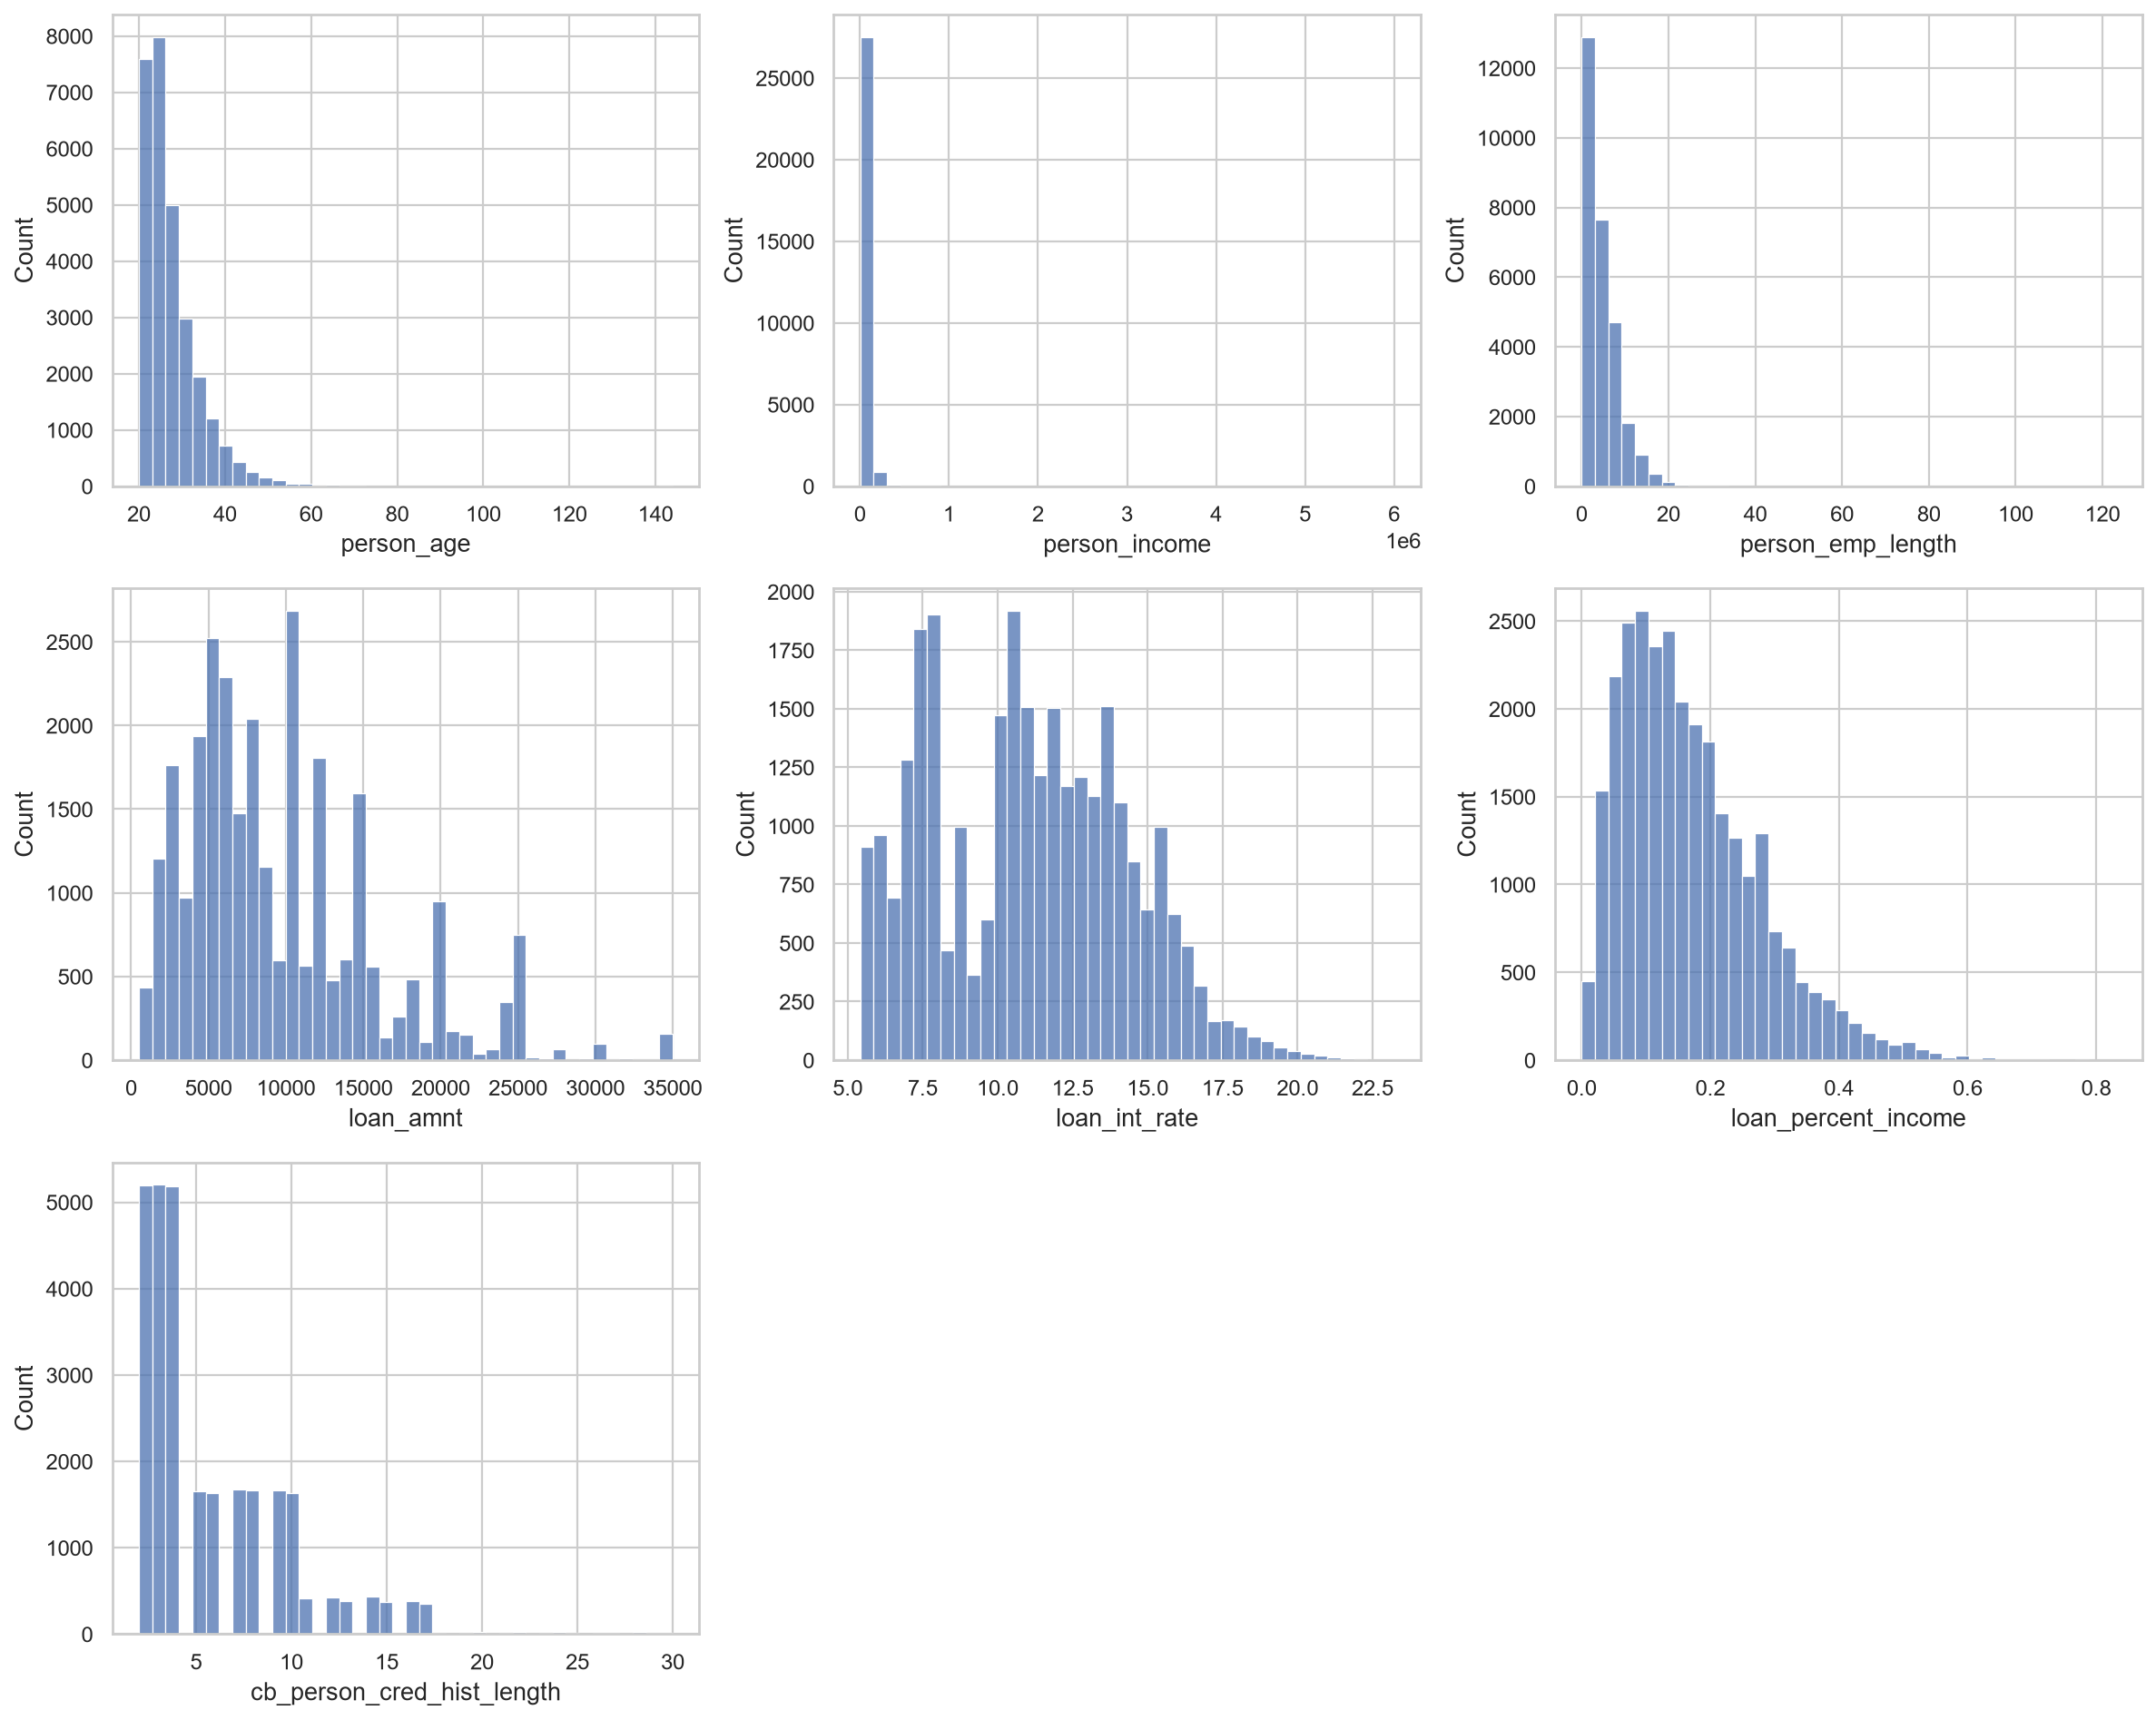

In [55]:
display(Image(filename=str(LAB / 'reports/figures/clean/histograms.png')))

### scatterplots

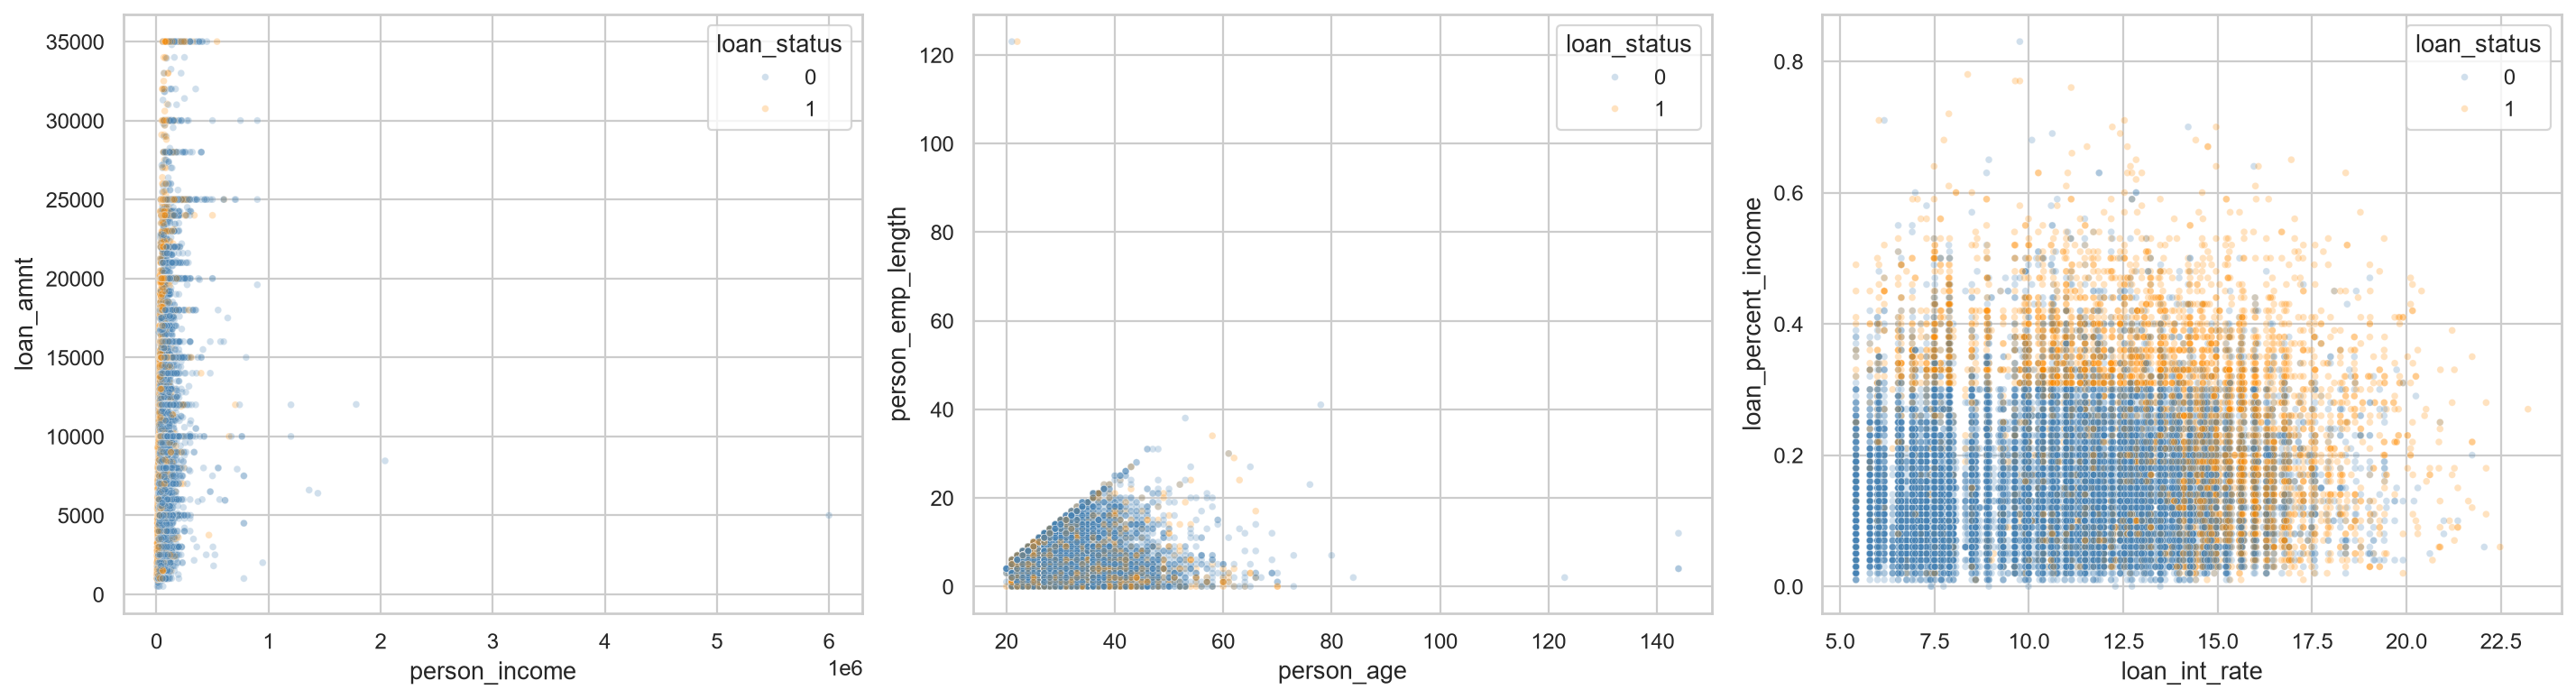

In [57]:
display(Image(filename=str(LAB / 'reports/figures/clean/scatterplots.png')))

### correlation_matrix

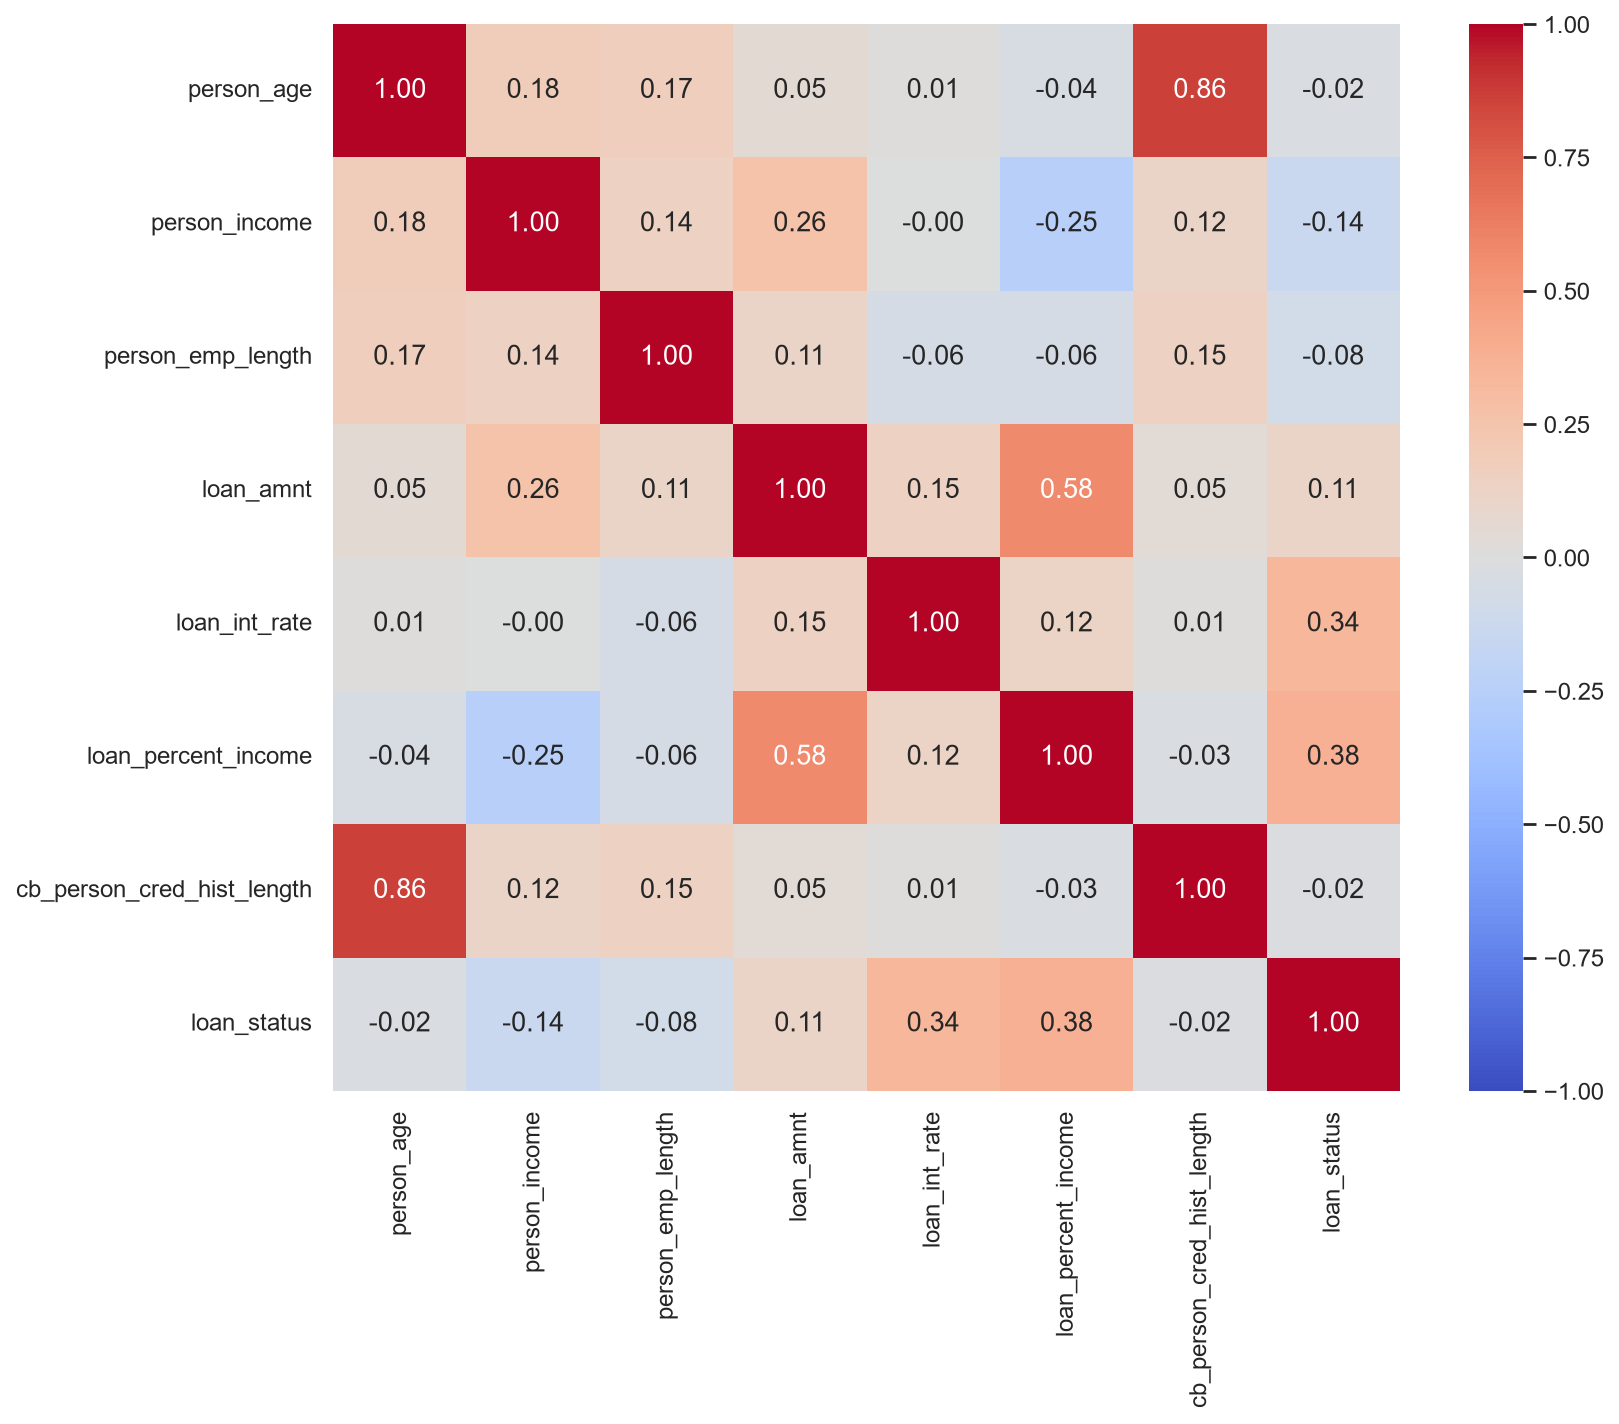

In [59]:
display(Image(filename=str(LAB / 'reports/figures/correlation_matrix.png')))

## Вывод
Лучшее по CV F1 — дерево глубины 8. Тестовая F1 ≈ 0.8055, ROC-AUC ≈ 0.9092. Precision высокий, но около трети дефолтов пропущено.

Ограничения: сохранены аномалии; оценка относится к данному эксперименту и не доказывает переносимость на другие данные.